#  Cox survival analysis

Run the project-paths cell first. Paths work from the project root or the notebooks folder.
Existing outputs are retained from the last run; historical path messages may show the former layout.
See [the project README](../README.md) for run order and current limitations.


In [ ]:
from pathlib import Path

# Locate the project whether the kernel starts in the root or notebooks/.
PROJECT_ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / 'requirements.txt').is_file()
     and (folder / 'notebooks').is_dir()
     and (folder / 'README.md').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Start this notebook from inside the Predictive maintenance for IoT project.')
RAW_DATA_DIR = PROJECT_ROOT / 'data' / 'raw' / 'cmapss'
PROCESSED_DATA_DIR = PROJECT_ROOT / 'data' / 'processed'
MODELS_DIR = PROJECT_ROOT / 'models'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
TABLES_DIR = PROJECT_ROOT / 'reports' / 'tables'
print(f'Project root: {PROJECT_ROOT}')


# Step 5b — Cox survival analysis for FD001

This is a **fixed-landmark baseline**, with one independent row per engine.
At cycle 30, summarize the first 30 sensor readings and predict the uncapped time
from cycle 30 to failure. Never summarize an engine's full future life as an input.

- Training-file engines are observed until failure (`event=1`).
- Test-file engines are still operating at their last observation (`event=0`).
  Their observed duration is follow-up since cycle 30, not time to failure.
- The separate test RUL labels reveal future failure times for evaluation only.
- Use the same 80/20 engine split as the corrected LSTM pipeline. Fit scaling and
  Cox coefficients only on training engines; select the penalizer on validation.
- This baseline freezes sensor covariates at cycle 30. Predictions at a later age
  condition on survival to that age, but do not incorporate later sensor changes.
  A dynamic landmark or time-varying model is a separate extension.

C-index measures ranking, not probability calibration. A score over 0.7 is a
heuristic, not a guarantee of useful maintenance decisions. Cox hazard ratios
multiply instantaneous hazard; they do not directly multiply remaining life.

Requires `lifelines` in the notebook environment. Run all cells in order.

In [1]:
from pathlib import Path
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from lifelines import CoxPHFitter
from lifelines.utils import concordance_index
from lifelines.statistics import proportional_hazard_test

LANDMARK = 30
PENALIZERS = [0.01, 0.1, 1.0, 10.0]
HORIZONS = [10, 20, 50]
DATA_DIR = RAW_DATA_DIR
OUTPUT_DIR = TABLES_DIR / 'survival_fd001'
FIGURE_DIR = FIGURES_DIR / 'survival_fd001'
SURVIVAL_DATA_DIR = PROCESSED_DATA_DIR / 'survival_fd001'
MODEL_DIR = MODELS_DIR / 'cox_fd001'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SURVIVAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

split_path = PROCESSED_DATA_DIR / 'lstm_fd001' / 'metadata.json'
if not split_path.exists():
    raise FileNotFoundError('Run the corrected LSTM data-preparation section first.')
split = json.loads(split_path.read_text(encoding='utf-8'))
SENSORS = split['sensor_names']
FEATURES = [f'{sensor}_mean_first30' for sensor in SENSORS]
TRAIN_IDS = split['train_units']
VAL_IDS = split['val_units']
assert set(TRAIN_IDS).isdisjoint(VAL_IDS)

## Prepare duration, event and covariates

Each covariate is the mean of one sensor over cycles 1–30. Training duration is
`failure_cycle - 30`; censored test duration is `last_observed_cycle - 30`.
The clock starts at cycle 30, conditional on reaching that landmark alive.
Engine IDs are row identifiers and are excluded from the model features.

In [2]:
COLUMNS = ['unit_number', 'time_in_cycles', 'setting_1', 'setting_2', 'setting_3'] + [f's_{i}' for i in range(1, 22)]
raw_train = pd.read_csv(DATA_DIR / 'train_FD001.txt', sep=r'\s+', header=None, names=COLUMNS)
raw_test = pd.read_csv(DATA_DIR / 'test_FD001.txt', sep=r'\s+', header=None, names=COLUMNS)

def landmark_table(raw, event_observed):
    rows = []
    for unit_id, engine in raw.groupby('unit_number', sort=True):
        engine = engine.sort_values('time_in_cycles')
        history = engine.loc[engine.time_in_cycles <= LANDMARK]
        if len(history) != LANDMARK or not np.array_equal(history.time_in_cycles, np.arange(1, LANDMARK + 1)):
            raise ValueError(f'Engine {unit_id}: expected complete cycles 1–{LANDMARK}')
        last_cycle = int(engine.time_in_cycles.max())
        if last_cycle <= LANDMARK:
            raise ValueError(f'Engine {unit_id}: no follow-up beyond landmark')
        row = {'unit_number': int(unit_id), 'duration': last_cycle - LANDMARK,
               'event': int(event_observed), 'last_observed_cycle': last_cycle}
        row.update(dict(zip(FEATURES, history[SENSORS].mean().to_numpy())))
        rows.append(row)
    return pd.DataFrame(rows).set_index('unit_number')

all_observed = landmark_table(raw_train, event_observed=1)
test_censored = landmark_table(raw_test, event_observed=0)
train_table = all_observed.loc[TRAIN_IDS].copy()
val_table = all_observed.loc[VAL_IDS].copy()
assert set(all_observed.index) == set(TRAIN_IDS) | set(VAL_IDS)
assert train_table.event.eq(1).all() and test_censored.event.eq(0).all()
assert train_table.duration.gt(0).all() and test_censored.duration.gt(0).all()

feature_scaler = StandardScaler().fit(train_table[FEATURES])
def model_frame(table):
    frame = pd.DataFrame(feature_scaler.transform(table[FEATURES]), index=table.index, columns=FEATURES)
    return frame.join(table[['duration', 'event']])

train_fit = model_frame(train_table)
val_fit = model_frame(val_table)
test_features = model_frame(test_censored)[FEATURES]
print(f'Training: {len(train_fit)} engines; validation: {len(val_fit)}; censored test: {len(test_censored)}')
print('Durations are uncapped. Each feature is standardized using training-engine statistics only.')
display(train_table.head())
train_table.to_csv(SURVIVAL_DATA_DIR / 'train_survival_table.csv')
val_table.to_csv(SURVIVAL_DATA_DIR / 'validation_survival_table.csv')
test_censored.to_csv(SURVIVAL_DATA_DIR / 'test_censored_survival_table.csv')

Training: 80 engines; validation: 20; censored test: 100
Durations are uncapped. Each feature is standardized using training-engine statistics only.


,duration,event,last_observed_cycle,s_2_mean_first30,s_3_mean_first30,s_4_mean_first30,s_7_mean_first30,s_8_mean_first30,s_11_mean_first30,s_12_mean_first30,s_13_mean_first30,s_14_mean_first30,s_15_mean_first30,s_17_mean_first30,s_20_mean_first30,s_21_mean_first30
unit_number,,,,,,,,,,,,,,,,
2,257,1,287,641.954000,1583.441000,1396.833667,554.593333,2388.002333,47.139333,522.414000,2387.997000,8137.295667,8.388810,391.233333,39.058000,23.438783
3,149,1,179,642.265333,1584.568333,1398.902000,554.340333,2388.033333,47.224667,522.156333,2388.027000,8138.287667,8.408420,391.500000,38.987333,23.377787
4,159,1,189,642.420667,1587.555333,1402.562000,553.917333,2388.069000,47.388667,521.844667,2388.071333,8131.909667,8.418753,392.300000,38.943000,23.339523
6,158,1,188,642.580667,1588.654000,1407.968667,553.224667,2388.128000,47.536000,521.470667,2388.128333,8122.039667,8.441820,393.266667,38.840000,23.307290
7,229,1,259,642.210667,1585.689333,1397.779333,554.308667,2388.007000,47.208667,522.214000,2388.006667,8149.233000,8.405267,391.766667,38.988667,23.402030


## Fit penalized Cox models and select on validation

Ridge penalization stabilizes correlated sensors. Select the highest validation
C-index; ties favor the stronger penalizer. Keep the selected model fitted on the
80 training engines, so the 20 validation engines remain held out. Test outcomes
are not loaded until after model selection and prediction.

In [3]:
trials, fitted_models = [], {}
for penalizer in PENALIZERS:
    candidate = CoxPHFitter(penalizer=penalizer, l1_ratio=0.0)
    candidate.fit(train_fit, duration_col='duration', event_col='event')
    validation_c = concordance_index(
        val_fit.duration, -candidate.predict_partial_hazard(val_fit[FEATURES]), val_fit.event
    )
    trials.append({'penalizer': penalizer, 'training_c_index': candidate.concordance_index_,
                   'validation_c_index': validation_c})
    fitted_models[penalizer] = candidate
trials = pd.DataFrame(trials).sort_values(['validation_c_index', 'penalizer'], ascending=[False, False])
best_penalizer = float(trials.iloc[0].penalizer)
cox_model = fitted_models[best_penalizer]
trials.to_csv(OUTPUT_DIR / 'penalizer_trials.csv', index=False)
display(trials)
print(f'Selected penalizer: {best_penalizer:g}')

,penalizer,training_c_index,validation_c_index
3,10.00,0.554063,0.680851
2,1.00,0.557582,0.680851
1,0.10,0.595969,0.638298
0,0.01,0.621561,0.537234


Selected penalizer: 10


## Hazard ratios and proportional-hazards checks

A hazard ratio above 1 associates a higher sensor mean with greater instantaneous
failure hazard, holding the other modeled covariates fixed. Below 1 associates it
with lower hazard. Here the increase is **one training-set standard deviation**
of that sensor's first-30-cycle mean. Correlated features and penalization affect
coefficients; these are associations, not causal effects or guaranteed physical signs.
Intervals and p-values are exploratory after penalizer selection.

,sensor,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,,
s_2_mean_first30,s_2,1.010061,0.944507,1.080166,0.769977
s_3_mean_first30,s_3,1.009585,0.944099,1.079613,0.780401
s_4_mean_first30,s_4,1.007428,0.941932,1.077478,0.829176
s_7_mean_first30,s_7,0.991943,0.927417,1.060959,0.813655
s_8_mean_first30,s_8,1.007477,0.941924,1.077593,0.828198
s_11_mean_first30,s_11,1.006255,0.940812,1.076251,0.855780
s_12_mean_first30,s_12,0.994431,0.929742,1.063620,0.870727
s_13_mean_first30,s_13,1.004903,0.939580,1.074767,0.886584
s_14_mean_first30,s_14,0.998466,0.934149,1.067211,0.963962


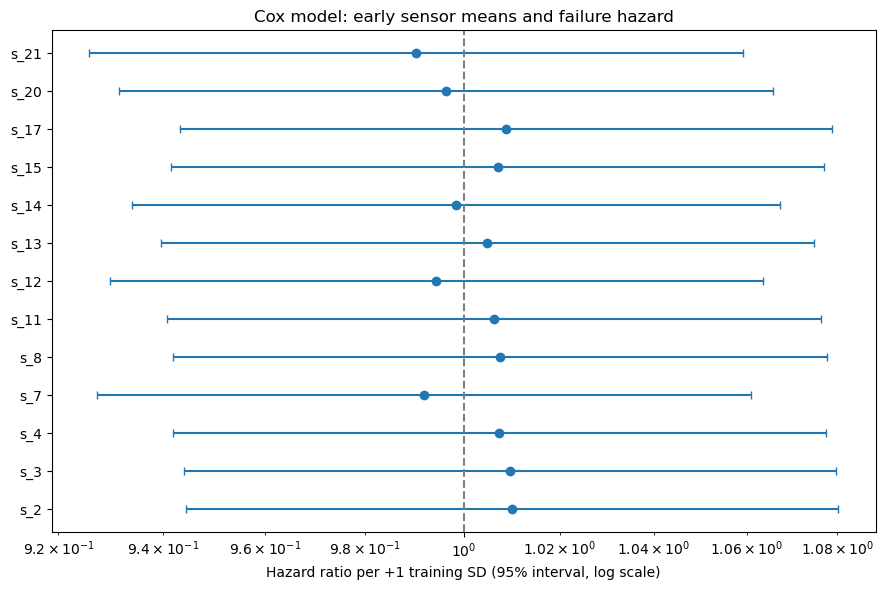

,test_statistic,p,-log2(p)
s_11_mean_first30,0.007244,0.932174,0.101329
s_12_mean_first30,0.000198,0.988766,0.016299
s_13_mean_first30,0.000239,0.987660,0.017913
s_14_mean_first30,0.035867,0.849790,0.234821
s_15_mean_first30,0.008557,0.926298,0.110451
s_17_mean_first30,0.005590,0.940403,0.088650
s_20_mean_first30,0.000084,0.992678,0.010602
s_21_mean_first30,0.003428,0.953315,0.068976
s_2_mean_first30,0.009407,0.922736,0.116010
s_3_mean_first30,0.011021,0.916392,0.125964


Small p-values flag potential proportional-hazards violations; these are exploratory checks, not proof of validity.


In [4]:
hazard_report = cox_model.summary.copy()
hazard_report['sensor'] = SENSORS
hazard_report['raw_mean_training'] = feature_scaler.mean_
hazard_report['raw_std_training'] = feature_scaler.scale_
hazard_report['interpretation'] = np.where(hazard_report['exp(coef)'] > 1,
    'Higher early sensor mean associated with higher hazard',
    'Higher early sensor mean associated with lower hazard')
hazard_report.to_csv(OUTPUT_DIR / 'hazard_ratios.csv')
display(hazard_report[['sensor', 'exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']])

hr = hazard_report['exp(coef)'].to_numpy()
low = hazard_report['exp(coef) lower 95%'].to_numpy()
high = hazard_report['exp(coef) upper 95%'].to_numpy()
fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(hr, np.arange(len(hr)), xerr=np.vstack([hr-low, high-hr]), fmt='o', capsize=3)
ax.axvline(1, color='gray', linestyle='--')
ax.set_yticks(np.arange(len(hr)), SENSORS)
ax.set_xscale('log')
ax.set_xlabel('Hazard ratio per +1 training SD (95% interval, log scale)')
ax.set_title('Cox model: early sensor means and failure hazard')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'hazard_ratios.png', dpi=160)
plt.show()

ph_test = proportional_hazard_test(cox_model, train_fit, time_transform='rank')
ph_test.summary.to_csv(OUTPUT_DIR / 'proportional_hazards_test.csv')
display(ph_test.summary)
print('Small p-values flag potential proportional-hazards violations; these are exploratory checks, not proof of validity.')

## Per-engine survival and probability of failure within K cycles

For age `a = last_observed_cycle - 30`, the conditional survival curve is
`S(a + k | x) / S(a | x)`. Failure probability in the next K cycles is one minus
that ratio. Sensor covariates remain the first-30-cycle means.

Use the fitted Breslow cumulative-hazard steps directly, including H(0)=0.
Export both the cycle-30 forecast and the forecast conditional on the test engine's
current age. Cox does not estimate an unrestricted parametric tail: horizons past
the last observed training event are reported as missing rather than extrapolated.

,last_observed_cycle,duration,maximum_supported_horizon,failure_within_10_cycles,failure_within_20_cycles,failure_within_50_cycles
unit_number,,,,,,
1,31,1,331.0,0.000000,0.000000,0.000000
2,49,19,313.0,0.000000,0.000000,0.000000
3,126,96,236.0,0.013621,0.040678,0.242017
4,106,76,256.0,0.000000,0.000000,0.143834
5,98,68,264.0,0.000000,0.000000,0.066106
6,105,75,257.0,0.000000,0.000000,0.118362
7,160,130,202.0,0.052456,0.132066,0.529941
8,166,136,196.0,0.062075,0.185730,0.701495
9,55,25,307.0,0.000000,0.000000,0.000000


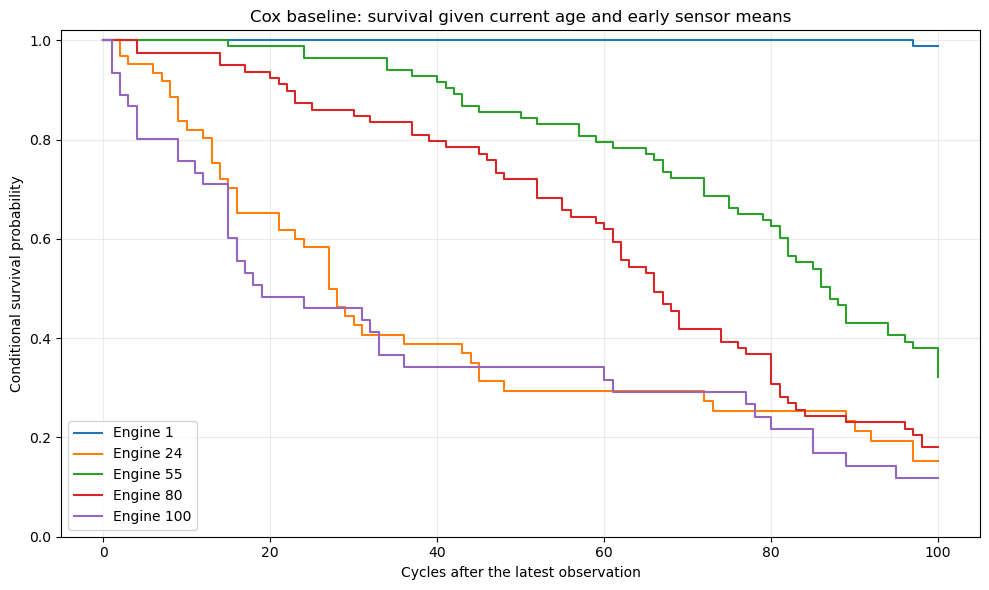

In [5]:
risk = cox_model.predict_partial_hazard(test_features).to_numpy()
base = cox_model.baseline_cumulative_hazard_.iloc[:, 0]
base_times = np.r_[0.0, base.index.to_numpy(dtype=float)]
base_hazard = np.r_[0.0, base.to_numpy(dtype=float)]
max_supported_time = float(base_times[-1])

def H0(times):
    times = np.asarray(times, dtype=float)
    if np.any(times < 0):
        raise ValueError('Time since landmark cannot be negative')
    return base_hazard[np.searchsorted(base_times, times, side='right') - 1]

def conditional_curves(horizons, ages, relative_risk):
    horizons = np.asarray(horizons, dtype=float)
    ages = np.asarray(ages, dtype=float)
    future_times = horizons[:, None] + ages[None, :]
    increments = H0(future_times) - H0(ages)[None, :]
    survival = np.exp(-increments * relative_risk[None, :])
    survival[future_times > max_supported_time] = np.nan
    return survival

full_times = np.arange(int(max_supported_time) + 1)
landmark_survival = conditional_curves(full_times, np.zeros(len(test_features)), risk)
future_cycles = np.arange(101)
ages = test_censored.duration.to_numpy(dtype=float)
current_survival = conditional_curves(future_cycles, ages, risk)
assert np.allclose(landmark_survival[0], 1.0)
assert np.allclose(current_survival[0, ages <= max_supported_time], 1.0)
assert np.nanmax(np.diff(current_survival, axis=0)) <= 1e-10
assert np.nanmin(current_survival) >= 0 and np.nanmax(current_survival) <= 1

pd.DataFrame(landmark_survival, index=full_times, columns=test_features.index).rename_axis('cycles_since_landmark').to_csv(OUTPUT_DIR / 'survival_from_cycle30.csv')
pd.DataFrame(current_survival, index=future_cycles, columns=test_features.index).rename_axis('future_cycles').to_csv(OUTPUT_DIR / 'conditional_survival.csv')
probabilities = test_censored[['last_observed_cycle', 'duration']].copy()
probabilities['maximum_supported_horizon'] = np.maximum(0, max_supported_time - ages)
for horizon in HORIZONS:
    probabilities[f'failure_within_{horizon}_cycles'] = 1 - conditional_curves([horizon], ages, risk)[0]
probabilities.to_csv(OUTPUT_DIR / 'failure_probabilities.csv')
display(probabilities.head(10))

fig, ax = plt.subplots(figsize=(10, 6))
for unit in [1, 24, 55, 80, 100]:
    column = test_features.index.get_loc(unit)
    ax.step(future_cycles, current_survival[:, column], where='post', label=f'Engine {unit}')
ax.set(xlabel='Cycles after the latest observation', ylabel='Conditional survival probability',
       title='Cox baseline: survival given current age and early sensor means', ylim=(0, 1.02))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'conditional_survival.png', dpi=160)
plt.show()

## Independent test evaluation

Only now load the separate RUL labels. True failure time since the landmark is
`last_observed_cycle + true_RUL - 30`. These complete evaluation labels have
`event=1`; they do not change the censored operational table or enter model fitting.
The test C-index ranks **failure times since cycle 30**, not current remaining RUL.
Its scope differs from the LSTM's last-window RMSE.

Also compute unweighted Brier scores for failure within each future horizon using
the provided complete future outcomes, restricted to supported horizons. Lower is
better; this assesses probabilities, while C-index assesses ranking. No IPCW is
needed here because the separate test truth supplies complete outcomes.

In [6]:
truth_values = pd.read_csv(DATA_DIR / 'RUL_FD001.txt', sep=r'\s+', header=None)[0].to_numpy()
assert len(truth_values) == len(test_censored)
assert np.array_equal(test_censored.index, np.arange(1, len(truth_values) + 1))
true_rul = pd.Series(truth_values, index=test_censored.index, name='true_remaining_cycles')
true_duration = test_censored.duration + true_rul
assert (true_duration > test_censored.duration).all()
test_c = concordance_index(true_duration, -risk, np.ones(len(true_duration)))
metrics = {
    'training_c_index': float(cox_model.concordance_index_),
    'validation_c_index': float(trials.iloc[0].validation_c_index),
    'test_landmark_c_index': float(test_c),
    'selected_penalizer': best_penalizer,
}
for horizon in HORIZONS:
    prediction = probabilities[f'failure_within_{horizon}_cycles']
    supported = prediction.notna()
    outcome = (true_rul <= horizon).astype(float)
    metrics[f'brier_failure_within_{horizon}'] = float(np.mean((prediction[supported] - outcome[supported]) ** 2))
    metrics[f'n_supported_at_{horizon}'] = int(supported.sum())
print(json.dumps(metrics, indent=2))
if test_c < 0.7:
    print('The test ranking is below the proposed 0.7 heuristic. This early-life baseline needs improvement before practical use.')
print('C-index does not establish calibrated failure probabilities. Review the Brier scores and hazard-assumption checks too.')
evaluation = probabilities.join(true_rul)
evaluation['true_failure_time_since_cycle30'] = true_duration
evaluation['relative_hazard_at_cycle30'] = risk
evaluation.to_csv(OUTPUT_DIR / 'test_evaluation.csv')

{
  "training_c_index": 0.5540626999360204,
  "validation_c_index": 0.6808510638297872,
  "test_landmark_c_index": 0.5757267737344989,
  "selected_penalizer": 10.0,
  "brier_failure_within_10": 0.05278657559097291,
  "n_supported_at_10": 100,
  "brier_failure_within_20": 0.0990042804069819,
  "n_supported_at_20": 100,
  "brier_failure_within_50": 0.1642064299297814,
  "n_supported_at_50": 100
}
The test ranking is below the proposed 0.7 heuristic. This early-life baseline needs improvement before practical use.
C-index does not establish calibrated failure probabilities. Review the Brier scores and hazard-assumption checks too.


## Save the trained model and reproducibility information

The model is a statistical baseline, not a validated maintenance policy. The
optional Weibull AFT alternative is not included in this first Cox implementation.
The LSTM and regression notebooks are unchanged by this notebook.

In [7]:
versions = {name: importlib.metadata.version(name) for name in ['lifelines', 'numpy', 'pandas', 'scikit-learn', 'scipy']}
metadata = {
    'model': 'Penalized Cox proportional hazards', 'landmark_cycle': LANDMARK,
    'feature_definition': 'Mean sensor reading over cycles 1 through 30, then training-only StandardScaler',
    'features': FEATURES, 'sensor_names': SENSORS,
    'train_units': TRAIN_IDS, 'validation_units': VAL_IDS,
    'duration_definition': 'Uncapped follow-up after cycle 30',
    'test_event_definition': '0 in operational censored table; true future failure labels used only for evaluation',
    'penalizer_candidates': PENALIZERS, 'selected_penalizer': best_penalizer,
    'maximum_supported_time_since_landmark': max_supported_time,
    'later_sensor_updates_used': False, 'python': platform.python_version(), 'versions': versions,
}
joblib.dump({'model': cox_model, 'scaler': feature_scaler, 'metadata': metadata}, MODEL_DIR / 'cox_bundle.pkl')
(MODEL_DIR / 'metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
(MODEL_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print(f'Model saved to {MODEL_DIR}; tables: {OUTPUT_DIR}; figures: {FIGURE_DIR}')

Model saved to saved_models\cox_fd001; reports and curves saved to outputs\survival_fd001


References: [lifelines survival regression](https://lifelines.readthedocs.io/en/latest/Survival%20Regression.html),
[Cox model prediction API](https://lifelines.readthedocs.io/en/latest/fitters/regression/CoxPHFitter.html),
[proportional-hazards diagnostics](https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html).